<a href="https://colab.research.google.com/github/Almodovare/Notebooks/blob/%D0%90%D0%BD%D0%94%D0%B0%D0%BD_%D0%9C%D0%B0%D0%B3_26/%D0%A3%D1%80%D0%BE%D0%BA_4_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# План:
1. Построение простых графиков
2. Срезы в наборе данных
3. Выбросы

# Загрузим данные

In [ ]:
import pandas as pd

In [ ]:
!git clone https://github.com/Almodovare/Training_Data

Cloning into 'Training_Data'...
remote: Enumerating objects: 195, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 195 (delta 4), reused 0 (delta 0), pack-reused 177 (from 2)
Receiving objects: 100% (195/195), 35.08 MiB | 12.51 MiB/s, done.
Resolving deltas: 100% (55/55), done.


In [ ]:
df = pd.read_csv('/content/Training_Data/mtcars.csv')

In [ ]:
df.columns # выведем названия столбцов для того, чтобы скопировать ниже

Index(['Unnamed: 0', 'MPG', 'Cylinders', 'Displacement', 'Horsepower',
       'Weight', 'Acceleration', 'Model Year', 'Origin'],
      dtype='object')

In [ ]:
df

,Unnamed: 0,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,0,18.0,8,307.0,130.0,3504.0,12.0,70,1
1,1,15.0,8,350.0,165.0,3693.0,11.5,70,1
2,2,18.0,8,318.0,150.0,3436.0,11.0,70,1
3,3,16.0,8,304.0,150.0,3433.0,12.0,70,1
4,4,17.0,8,302.0,140.0,3449.0,10.5,70,1
...,...,...,...,...,...,...,...,...,...
393,393,27.0,4,140.0,86.0,2790.0,15.6,82,1
394,394,44.0,4,97.0,52.0,2130.0,24.6,82,2
395,395,32.0,4,135.0,84.0,2295.0,11.6,82,1
396,396,28.0,4,120.0,79.0,2625.0,18.6,82,1


# Построение графиков

<Axes: >

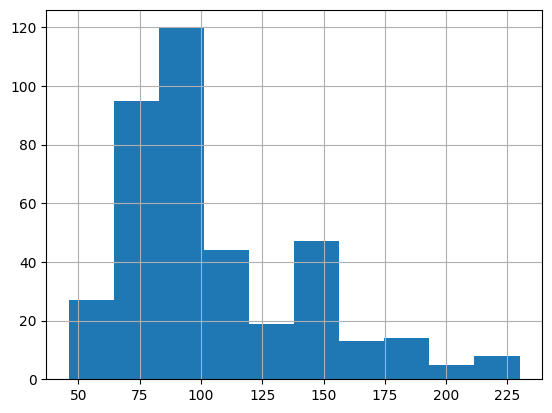

In [ ]:
df['Horsepower'].hist() # Построение гистограммы

<Axes: >

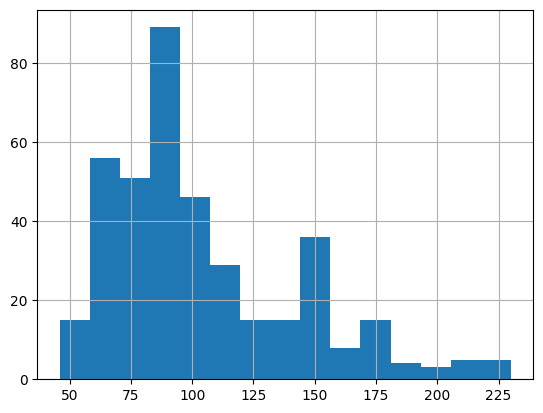

In [ ]:
df['Horsepower'].hist(bins = 15) # Построение гистограммы с указанием количества столбцов

<Axes: ylabel='Frequency'>

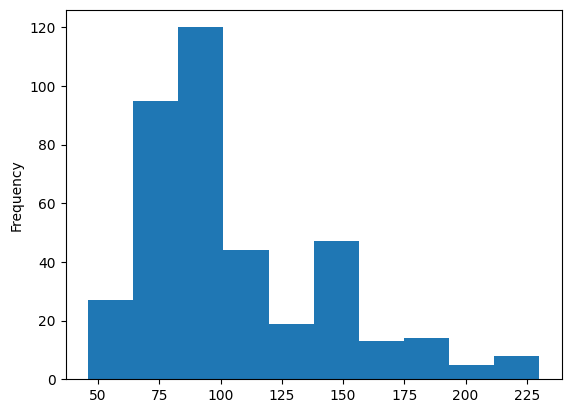

In [ ]:
df['Horsepower'].plot( kind = 'hist') # Построение гистограммы методом .plot

In [ ]:
# В методе .plot() первым аргументом указывается тип графика:
# hist - для гистограммы
# box - для ящика с усами
# pie - для круговой диаграммы
# scatter - диаграмма рассеивания
# line - для линейного графика

<Axes: >

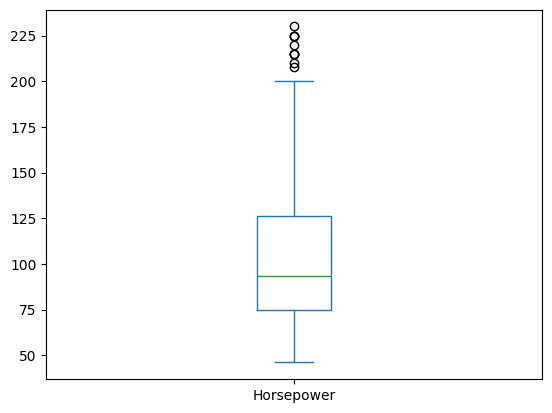

In [ ]:
df['Horsepower'].plot(kind = "box") # Построение ящика с усами

<Axes: >

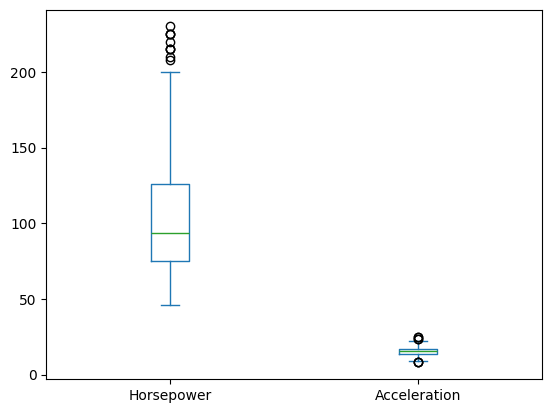

In [ ]:
df[['Horsepower','Acceleration']].plot( kind ="box") # при отборе нескольких
# столбцов они перечисляются в виде массива, то есть в
# дополнительных квадратных скобках

In [ ]:
# Вывод: по графику наблюдается наличие нескольких точек- выбросов,
# медиана смещена к Q1, усы не равной длины

<Axes: ylabel='Frequency'>

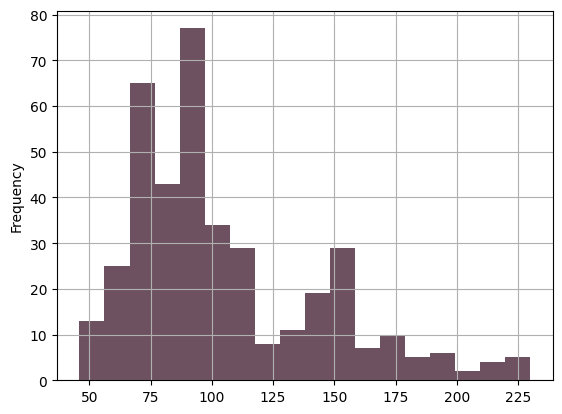

In [ ]:
df['Horsepower'].plot( kind = 'hist', color = "#6E5160", bins = 18, grid = True)

# Срезы в наборе данных

In [ ]:
# Для того, чтобы отобрать часть df в новый набр данных, используют
# методы .loc (location) и .iloc (index location), отличающиеся тем, что
# loc отбирает по именам строк и столбцов, а iloc по номерам

In [ ]:
df.iloc[:,1] # аргументы указываются в квадратных скобках,
# первый из них означает номер или диапазон строк, а второй - столбцов

,MPG
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0
...,...
393,27.0
394,44.0
395,32.0
396,28.0


In [ ]:
# Двоеточие указывает на отбор всех строк

In [ ]:
df.columns

Index(['Unnamed: 0', 'MPG', 'Cylinders', 'Displacement', 'Horsepower',
       'Weight', 'Acceleration', 'Model Year', 'Origin'],
      dtype='object')

In [ ]:
df.loc[:,'MPG']

,MPG
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0
...,...
393,27.0
394,44.0
395,32.0
396,28.0


In [ ]:
# Если нужно отобрать диапазон столбцов:
df.iloc[:,2:4] # заметим, что метод iloc не включает последнее число диапазона
# а loc включает
df.loc[:,"MPG":'Horsepower']

,MPG,Cylinders,Displacement,Horsepower
0,18.0,8,307.0,130.0
1,15.0,8,350.0,165.0
2,18.0,8,318.0,150.0
3,16.0,8,304.0,150.0
4,17.0,8,302.0,140.0
...,...,...,...,...
393,27.0,4,140.0,86.0
394,44.0,4,97.0,52.0
395,32.0,4,135.0,84.0
396,28.0,4,120.0,79.0


In [ ]:
# Если нужно отобрать диапазон строк,
# похожие действия предпринимаются с первым аргументом
df.iloc[2:6,2:4]

,Cylinders,Displacement
2,8,318.0
3,8,304.0
4,8,302.0
5,8,429.0


In [ ]:
# Если нужно отобрать не диапазон, а конкретные строчки или столбцы
# то они указываются в виде массива
df.loc[:,['MPG', 'Horsepower']]

,MPG,Horsepower
0,18.0,130.0
1,15.0,165.0
2,18.0,150.0
3,16.0,150.0
4,17.0,140.0
...,...,...
393,27.0,86.0
394,44.0,52.0
395,32.0,84.0
396,28.0,79.0


In [ ]:
df.loc[[5,8,27],['MPG', 'Horsepower','Origin']]

,MPG,Horsepower,Origin
5,15.0,198.0,1
8,14.0,225.0,1
27,11.0,210.0,1


In [ ]:
 df_1 = df.loc[[5,8,27],['MPG', 'Horsepower','Origin']]

# Выбросы

In [ ]:
# Вычислим точки -выбросы в переменной Horsepower
# 1)методом полутора интерквартильных размахов и 2)методом трех сигм

In [ ]:
Q1 = df['Horsepower'].quantile(0.25) # найдем первый квартиль
Q3 = df['Horsepower'].quantile(0.75) # найдем третий квартиль
IQR = Q3-Q1 # найдем интерквартильный размах

In [ ]:
UB = Q3 + 1.5*IQR # вычислим нижнюю и верхнюю границы, отделяющие выбросы от основного массива
LB = Q1 - 1.5*IQR
print(UB, LB)

202.5 -1.5


In [ ]:
df_notout = df[(df.Horsepower > LB) & (df.Horsepower < UB)]
# отберем в отдельный датафрейм наблюдения, удовлетворяющие условию
# " больше нижней границы, но меньше верхней"

In [ ]:
df_notout['Horsepower'].unique() # выведем уникальные значения

array([130., 165., 150., 140., 198., 190., 170., 160.,  95.,  97.,  85.,
        88.,  46.,  87.,  90., 113., 200., 193., 100., 105., 175., 153.,
       180., 110.,  72.,  86.,  70.,  76.,  65.,  69.,  60.,  80.,  54.,
       155., 112.,  92., 145., 137., 158., 167.,  94., 107.,  49.,  75.,
        91., 122.,  67.,  83.,  78.,  52.,  61.,  93., 148., 129.,  96.,
        71.,  98., 115.,  53.,  81.,  79., 120., 152., 102., 108.,  68.,
        58., 149.,  89.,  63.,  48.,  66., 139., 103., 125., 133., 138.,
       135., 142.,  77.,  62., 132.,  84.,  64.,  74., 116.,  82.])

In [ ]:
out = df[(df.Horsepower < LB) | (df.Horsepower > UB)]

In [ ]:
out['Horsepower'].unique() # выведем выбросы

array([220., 215., 225., 210., 208., 230.])